In [1]:
%matplotlib inline

from IPython.display import Image

import qutip 
import qutip_qip.operations 
from qutip_qip.circuit import QubitCircuit, Gate, CircuitSimulator
from qutip import basis, tensor, qeye, sigmax, sigmaz
import random
import numpy as np


In [28]:
#MI ESTADO INICIAL <3
a=5
b=2
psi = (a*basis(2,0) + b*basis(2,1)).unit()
physical = [basis(2,0)]*4
state1 = tensor([psi]+physical)
state1

#np.set_printoptions(linewidth=200)
#print(state1.full().real.T)

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.92847669]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.37139068]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]

In [29]:
#MIS AUTOVECTORES INICIALES <3
state1.ptrace(0).eigenstates()

(array([1.38777878e-17, 1.00000000e+00]),
 array([Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[ 0.37139068]
         [-0.92847669]]                                                       ,
        Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[-0.92847669]
         [-0.37139068]]                                                       ],
       dtype=object))

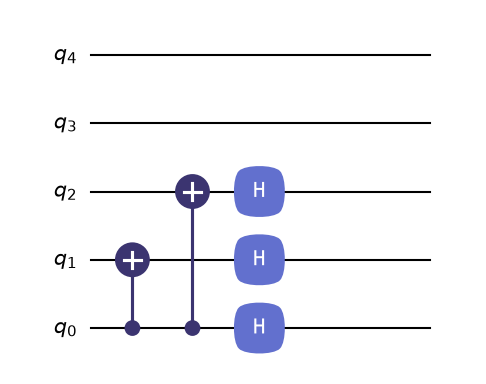

In [30]:
#CIRCUITO CODIFICADOR (phase-flip): primero CNOTs (codigo de repeticion) y DESPUES H en los 3 qubits
qenc = QubitCircuit(5, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
qenc.add_gate("H", targets=[0])
qenc.add_gate("H", targets=[1])
qenc.add_gate("H", targets=[2])
qenc

In [31]:
#ESTADO CODIFICADO
encoded_state = qenc.run(state=state1)
encoded_state

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]]

In [42]:
#GENERAR EL ESTADO CON ERROR
error_op = [qeye(2)]*5
flip_qubit = random.randint(0,2)
print("Bit-flipping qubit {}".format(flip_qubit))
error_op[flip_qubit] *= sigmaz()

error0 = [qeye(2)]*5
error0[0] *= sigmaz()

error1 = [qeye(2)]*5
error1[1] *= sigmaz()

error2 = [qeye(2)]*5
error2[2] *= sigmaz()

#APLICA EL ERROR QUE QUIERAS: error0, error1, error2, error_op
errorstate=tensor(error_op) * encoded_state

Bit-flipping qubit 0


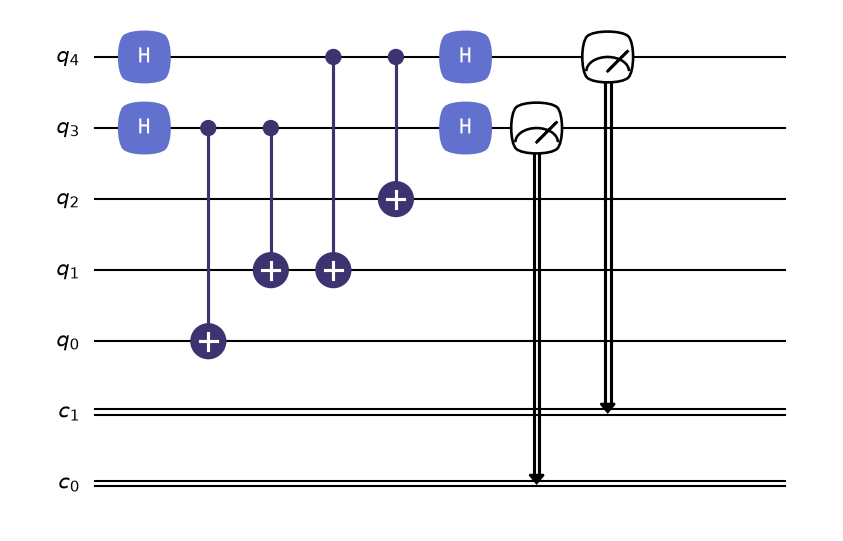

In [33]:
#CIRCUITO PARA CORREGIR A PARTIR DE LAS MEDIDAS 
qdet1=QubitCircuit(5, reverse_states=False, num_cbits=2)

qdet1.add_gate("H", targets=[3])
qdet1.add_gate("H", targets=[4])

qdet1.add_gate("CNOT", controls=[3], targets=[0])
qdet1.add_gate("CNOT", controls=[3], targets=[1])

qdet1.add_gate("CNOT", controls=[4], targets=[1])
qdet1.add_gate("CNOT", controls=[4], targets=[2])

qdet1.add_gate("H", targets=[3])
qdet1.add_gate("H", targets=[4])

qdet1.add_measurement("M0", targets=[3], classical_store=0)
qdet1.add_measurement("M1", targets=[4], classical_store=1)

qdet1



In [43]:
sim_qdet1 = CircuitSimulator(qdet1)
resultado_noerror = sim_qdet1.run(state=encoded_state)
resultado_error = sim_qdet1.run(state=errorstate)

In [44]:
bits_clasicos_noerror = resultado_noerror.cbits
bits_clasicos_error = resultado_error.cbits
bits_clasicos_error

[[np.int64(1), np.int64(0)]]

In [45]:
estado_final_error = resultado_error.get_final_states()[0]
estado_final_noerror = resultado_noerror.get_final_states()[0]
estado_final_error

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[ 0.        ]
 [ 0.        ]
 [ 0.45957252]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.19695965]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.19695965]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.45957252]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [-0.19695965]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [-0.45957252]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [-0.45957252]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [-0.19695965]
 [ 0.        ]]

In [46]:
#CORRECCION A MANO, NOS DA EL ESTADO CORREGIDO
corr_op = [qeye(2)]*5
q3, q4 = bits_clasicos_error[0]
if(q3 == 1 and q4== 0):
    corr_op[0]*= sigmaz()
if(q3 == 1 and q4== 1):
    corr_op[1]*= sigmaz()
if(q3 == 0 and q4== 1):
    corr_op[2]*= sigmaz()



manualcorr=tensor(corr_op) * errorstate
manualcorr


Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]]

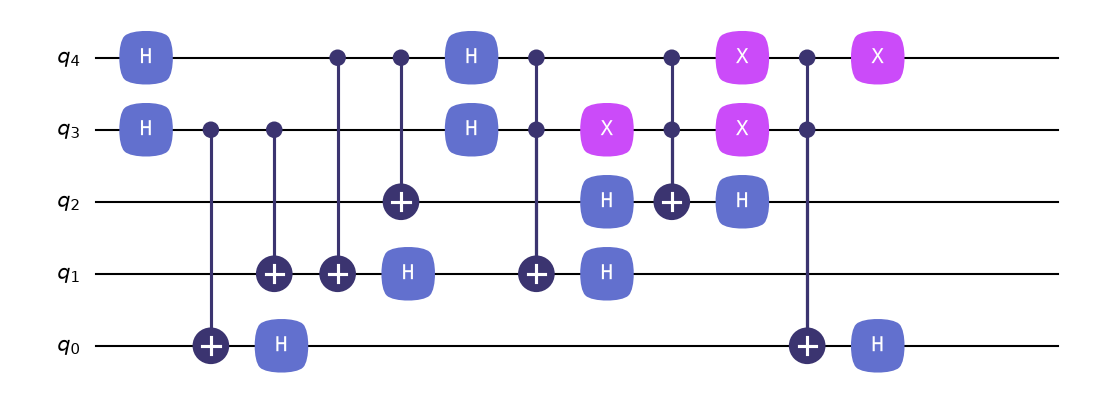

In [47]:
#CIRCUITO CORRECCION CUANTICA
qcorr=QubitCircuit(5, reverse_states=False)

qcorr.add_gate("H", targets=[3])
qcorr.add_gate("H", targets=[4])

qcorr.add_gate("CNOT", controls=[3], targets=[0])
qcorr.add_gate("CNOT", controls=[3], targets=[1])

qcorr.add_gate("CNOT", controls=[4], targets=[1])
qcorr.add_gate("CNOT", controls=[4], targets=[2])

qcorr.add_gate("H", targets=[3])
qcorr.add_gate("H", targets=[4])

qcorr.add_gate("H", targets=[1])
qcorr.add_gate("TOFFOLI", controls=[3,4], targets=[1])
qcorr.add_gate("H", targets=[1])

qcorr.add_gate("X", targets=[3])
qcorr.add_gate("H", targets=[2])
qcorr.add_gate("TOFFOLI", controls=[3,4], targets=[2])
qcorr.add_gate("H", targets=[2])

qcorr.add_gate("X", targets=[3])
qcorr.add_gate("X", targets=[4])
qcorr.add_gate("H", targets=[0])
qcorr.add_gate("TOFFOLI", controls=[3,4], targets=[0])
qcorr.add_gate("H", targets=[0])
qcorr.add_gate("X", targets=[4])
qcorr


In [48]:
#CORRIGE QUANTICAMENTE
quantumcorr=qcorr.run(state=errorstate)
quantumcorr

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.        ]
 [0.        ]
 [0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.45957252]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.19695965]
 [0.        ]]

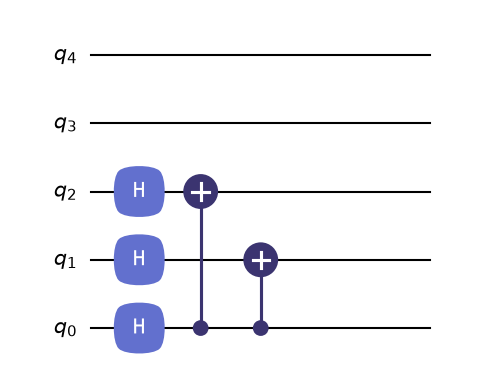

In [49]:
#CIRCUITO DECOD
decod=QubitCircuit(5, reverse_states=False)
decod.add_gate("H", targets=[0])
decod.add_gate("H", targets=[1])
decod.add_gate("H", targets=[2])
decod.add_gate("CNOT", controls=[0], targets=[2])
decod.add_gate("CNOT", controls=[0], targets=[1])
decod


In [52]:
#ELEGIR SI DECODIFICAR EL ESTADO CORREGIDO MANUALMENTE O QUANTICAMENTE (manualcorr, quantumcorr)
decoded_state = decod.run(state=manualcorr)
decoded_state

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.92847669]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.37139068]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]

In [53]:
decoded_state.ptrace(0).eigenstates()

(array([-2.77555756e-17,  1.00000000e+00]),
 array([Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[ 0.37139068]
         [-0.92847669]]                                                       ,
        Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[-0.92847669]
         [-0.37139068]]                                                       ],
       dtype=object))